# Parte 2 - Exploração dos dados (Slashdot)

Este notebook apresenta o dataset Slashdot e sua organização como uma rede de relações dirigidas entre usuários. A descrição das colunas, a leitura do arquivo e a visualização dos registros ajudam a compreender os dados utilizados na Parte 2 do projeto.

As buscas, os caminhos mínimos e as medições de desempenho (Teoria dos Grafos) estão em `02_grafos_algoritmos.ipynb`.

## Pergunta de pesquisa

> No Slashdot, quando um usuário marca outro como amigo ou inimigo, como o tipo de marcação se relaciona com o número mínimo de passos para voltar da pessoa marcada até quem fez a marcação?

## 1. Sobre o dataset

O Slashdot é um site de notícias sobre tecnologia. O recurso Slashdot Zoo permite que um usuário marque outro como amigo ou inimigo. O dataset reúne essas relações.

Vamos utilizar o arquivo `soc-sign-Slashdot090221.txt.gz`, de 21 de fevereiro de 2009, disponível no [SNAP / Stanford](https://snap.stanford.edu/data/soc-sign-Slashdot090221.html).

Cada linha representa uma relação de um usuário para outro. Por isso, a rede é dirigida: uma marcação de A para B não significa que B também marcou A.

Além disso, cada marcação tem um peso, que é o seu sinal: `1` para amigo e `-1` para inimigo. Por isso, a rede também é ponderada.

| Coluna | Significado |
| --- | --- |
| `origem` | Identificador do usuário que fez a marcação |
| `destino` | Identificador do usuário que recebeu a marcação |
| `sinal` | `1` para amigo e `-1` para inimigo |

## 2. Preparar a leitura

Selecione o Python do ambiente `.venv` do projeto. O bloco abaixo permite importar `ler_dataset`, a função que já criamos no `io.py`. Ele funciona com o notebook aberto pela raiz do projeto ou pela pasta `notebooks`.

In [1]:
# [IA] ChatGPT - apoio na configuracao dos caminhos para importar o projeto
from pathlib import Path
import sys

import pandas as pd

pasta_projeto = Path.cwd()
if pasta_projeto.name == "notebooks":
    pasta_projeto = pasta_projeto.parent

if str(pasta_projeto) not in sys.path:
    sys.path.insert(0, str(pasta_projeto))

from src.graphs.io import ler_dataset

## 3. Ler o arquivo

O arquivo deve estar em `data/dataset_parte2/`. A função `ler_dataset` abre o `.gz`, ignora os comentários e valida os dados antes de devolver a tabela. Não é necessário descompactar.

`dados.head()` mostra as cinco primeiras linhas, para vermos como as informações estão organizadas.

In [2]:
# [IA] ChatGPT - apoio na leitura e exibicao inicial do dataset
caminho_dataset = pasta_projeto / "data" / "dataset_parte2" / "soc-sign-Slashdot090221.txt.gz"
dados = ler_dataset(caminho_dataset)
dados.head()

,origem,destino,sinal
0,0,1,1
1,0,2,1
2,0,3,1
3,0,4,1
4,0,5,1


## 4. Pilar estrutural

As células abaixo levantam a estrutura da tabela: dimensões, tipos das colunas, valores nulos, linhas duplicadas, auto-laços e contagem dos sinais. Elas só produzem os números. A leitura de cada resultado é escrita pelo grupo logo abaixo.

### 4.1 Dimensões e tipos das colunas

In [3]:
# [IA] Claude – sintaxe pandas (shape, dtypes, memory_usage)
linhas, colunas = dados.shape
print(f"Linhas (relações): {linhas}")
print(f"Colunas: {colunas}")
print(f"Memória: {dados.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
dados.dtypes.to_frame("tipo")

Linhas (relações): 549202
Colunas: 3
Memória: 12.6 MB


,tipo
origem,int64
destino,int64
sinal,int64


**Interpretação**

O dataset possui 549.202 registros e 3 colunas. Cada linha representa uma relação dirigida entre dois usuários, ou seja, uma aresta do grafo. O dataset possui 549.202 arcos, aproximadamente 9,84% acima da referência de 500 mil indicada no enunciado. Justificamos a sua escolha por representar uma rede real dirigida, com relações positivas e negativas, adequada à análise dos algoritmos exigidos. Optamos por preservar a rede completa, pois remover arcos apenas para reduzir o tamanho poderia alterar graus, conectividade, caminhos e ciclos negativos. A viabilidade dos algoritmos mais custosos será avaliada pelos tempos e recursos medidos nos experimentos. Esta exploração usa a rede completa. Os experimentos com os algoritmos usam recortes com 10%, 50% e 100% dos usuários, descritos na seção 5 do notebook `02_grafos_algoritmos.ipynb`.

Embora armazenadas como `int64`, `origem` e `destino` são atributos nominais que identificam usuários, por isso não faz sentido calcular a média deles. `sinal` também é nominal e binário: +1 e −1 são códigos das categorias amigo e inimigo, não medidas de intensidade, e considerar amigo "melhor" é um julgamento que não define uma escala ordinal no dataset. As três colunas não informam idade, localização ou motivos das relações, limitando a análise à estrutura da rede e aos sinais das conexões. Os 12,6 MB ocupados pela tabela são modestos para um computador atual, mas construir o grafo e executar algoritmos pode exigir mais memória e processamento.

### 4.2 Quantidade de usuários (nós)

In [4]:
# [IA] Claude – sintaxe pandas (nunique, concat)
usuarios = pd.concat([dados["origem"], dados["destino"]]).nunique()
pd.Series(
    {
        "usuários que aparecem como origem": dados["origem"].nunique(),
        "usuários que aparecem como destino": dados["destino"].nunique(),
        "usuários no total (origem ou destino)": usuarios,
    },
    name="quantidade",
).to_frame()

,quantidade
usuários que aparecem como origem,44044
usuários que aparecem como destino,70284
usuários no total (origem ou destino),82140


**Interpretação**

O grafo possui ordem |V| = 82.140, que corresponde aos usuários distintos na união de `origem` e `destino`. Somar as duas contagens (44.044 + 70.284) contaria duas vezes os 32.188 usuários presentes em ambos os grupos. Existem 11.856 usuários que aparecem apenas como origem e têm, portanto, grau de entrada zero: fizeram marcações, mas não receberam nenhuma registrada neste dataset. Outros 38.096 aparecem apenas como destino, com grau de saída zero: receberam marcações, mas não fizeram nenhuma registrada. Isso mostra que receber marcações abrange mais usuários do que fazê-las.

Uma BFS que respeite a direção dos arcos, iniciada em um usuário que só aparece como destino, visita somente ele. Para explorar outros nós, a fonte precisa ter grau de saída positivo. Isso permite iniciar a exploração, mas não garante alcançar toda a rede. A diferença de quatro usuários em relação ao cabeçalho do arquivo (82.144) pode decorrer de nós isolados, que não aparecem nas linhas de arestas, ou de uma inconsistência nos metadados. Essa contagem sozinha não confirma a causa.

Os identificadores **11680**, **73373**, **78482** e **79625** não aparecem como origem nem como destino. Se forem nós isolados, a ausência é compatível com MNAR, pois depende do próprio grau: quem tem grau zero nunca aparece em uma lista de arestas. A modelagem explícita indicada para MNAR exigiria assumir que eram nós isolados, o que o arquivo não confirma. Por isso, registramos a diferença e limitamos a análise aos 82.140 usuários observados.

### 4.3 Valores nulos

In [5]:
# [IA] Claude – sintaxe pandas (isna)
dados.isna().sum().to_frame("nulos")

,nulos
origem,0
destino,0
sinal,0


**Interpretação**

Não foram encontrados valores nulos em `origem`, `destino` e `sinal`. Portanto, não é necessário remover registros nem imputar valores nessas colunas. Entretanto, a ausência de um arco significa apenas que não há marcação registrada: pode haver desconhecimento, indiferença ou uma opinião não expressa, situações que o dataset não distingue. Se o objetivo fosse conhecer essas opiniões não expressas, MNAR seria uma hipótese plausível, pois a decisão de registrar uma marcação pode depender da própria opinião. Isso, porém, não é comprovável apenas com os dados disponíveis.

Assim, manteremos os usuários e as relações observadas, sem criar arcos nem atribuir sinais às relações não registradas, pois isso inventaria informações e alteraria graus, caminhos e conectividade. As conclusões ficam restritas à rede registrada: um caminho indica uma sequência de marcações, não necessariamente amizade, e a ausência de caminho não comprova ausência de vínculo social.

### 4.4 Linhas duplicadas

In [6]:
# [IA] Claude – sintaxe pandas (duplicated)
pd.Series(
    {
        "linhas idênticas (origem, destino e sinal)": dados.duplicated().sum(),
        "mesmo par (origem, destino) repetido": dados.duplicated(subset=["origem", "destino"]).sum(),
    },
    name="quantidade",
).to_frame()

,quantidade
"linhas idênticas (origem, destino e sinal)",0
"mesmo par (origem, destino) repetido",0


**Interpretação**

Não foram encontradas linhas idênticas nem pares ordenados (`origem`, `destino`) repetidos. Portanto, não é necessário remover duplicatas. Existe no máximo um arco em cada direção entre dois usuários, sem arcos paralelos. Para classificar o grafo como simples, também precisamos verificar a ausência de auto-laços, o que é feito na próxima seção. Cada linha corresponde a um arco distinto. Logo, o tamanho do grafo é |E| = 549.202, considerando todos os registros carregados.

Também não existem sinais conflitantes para um mesmo par ordenado, o que dispensa uma regra para escolher entre +1 e −1 ou para combinar registros. O arco de A para B e o de B para A são diferentes e podem coexistir: representam marcações nos dois sentidos e não são duplicatas. A estrutura de dados permite representar um multigrafo, pois `adicionar_arco` acrescenta cada arco sem verificar repetições. Entretanto, como o dataset não possui pares ordenados repetidos e cada linha é carregada uma única vez, o grafo carregado não apresenta arcos paralelos.

### 4.5 Auto-laços (usuário que marca a si mesmo)

In [7]:
# [IA] Claude – sintaxe pandas (filtro booleano)
auto_lacos = dados[dados["origem"] == dados["destino"]]
print(f"Auto-laços: {len(auto_lacos)}")
auto_lacos.head()

Auto-laços: 0


,origem,destino,sinal


**Interpretação**

Não foram encontrados auto-laços: nenhum usuário marcou a si mesmo como amigo ou inimigo nos registros carregados. Portanto, não há auto-laços a remover. Juntando esse resultado à ausência de arcos paralelos verificada na seção 4.4, o grafo construído é dirigido e simples. A densidade |E| / (|V| · (|V| − 1)) é adequada, pois cada usuário pode ter arcos para os outros |V| − 1 usuários, excluindo a si mesmo.

Se o sinal for usado como peso, um auto-laço com peso −1 seria um ciclo negativo de comprimento 1. Sem auto-laços, o menor ciclo possível tem comprimento 2, como de A para B e de volta para A. A ausência de automarcações é uma característica dos dados analisados, mas não permite concluir se o site as proíbe ou se elas foram removidas na preparação do dataset.

### 4.6 Contagem dos sinais

In [8]:
# [IA] Claude – sintaxe pandas (value_counts)
contagem = dados["sinal"].value_counts().to_frame("quantidade")
contagem["proporção (%)"] = (contagem["quantidade"] / len(dados) * 100).round(2)
contagem

,quantidade,proporção (%)
sinal,,
1,425072,77.4
-1,124130,22.6


**Interpretação**

Foram encontrados apenas os sinais +1 e −1, confirmando as duas categorias previstas: 425.072 marcações de amigo (77,4%) e 124.130 de inimigo (22,6%). As classes são desbalanceadas, com aproximadamente 3,42 marcações de amigo para cada marcação de inimigo. Os pesos negativos vêm do dataset original, o que atende ao requisito de não serem inventados pelo grupo. Essa predominância descreve as marcações registradas, mas não explica suas motivações nem revela se os sinais negativos estão concentrados em poucos usuários. Para isso, é preciso analisar os graus de entrada e de saída separados por sinal.

O Dijkstra não deve ser aplicado diretamente com esses pesos negativos. A transformação para pesos não negativos e o seu significado serão justificados no notebook `02_grafos_algoritmos.ipynb`, deixando claro que ela pode mudar os caminhos mínimos. A presença de arcos negativos não garante ciclos negativos: é necessário um ciclo cuja soma dos pesos seja negativa. No caso de A para B e de volta para A, ambos os arcos precisam ter peso −1.

### 4.7 Densidade do grafo

A célula abaixo monta o grafo com `montar_grafo_dataset` e usa o método `metricas()` da classe `GrafoDirigido`, o mesmo da Parte 1. A densidade dirigida é |E| / (|V| · (|V| − 1)). A célula só produz os números. A leitura é escrita pelo grupo.

In [9]:
# [IA] Claude – uso de montar_grafo_dataset e metricas() para calcular a densidade
from src.graphs.io import montar_grafo_dataset

grafo = montar_grafo_dataset(dados)
metricas = grafo.metricas()
pd.Series(
    {
        "ordem |V| (usuários)": metricas["ordem"],
        "tamanho |E| (marcações)": metricas["tamanho"],
        "pares ordenados possíveis |V|·(|V|−1)": metricas["ordem"] * (metricas["ordem"] - 1),
        "densidade |E| / (|V|·(|V|−1))": f"{metricas['densidade']:.3e}",
    },
    name="valor",
    dtype="object",
).to_frame()

,valor
ordem |V| (usuários),82140
tamanho |E| (marcações),549202
pares ordenados possíveis |V|·(|V|−1),6746897460
densidade |E| / (|V|·(|V|−1)),8.140e-05


**Interpretação**

Das marcações que poderiam existir entre os 82.140 usuários do Slashdot, apenas 0,0081% aparecem no dataset. Isso equivale a cerca de 8 marcações para cada 100 mil possíveis. Embora a rede tenha 549.202 marcações, elas ocupam uma parcela pequena de todas as conexões que poderiam existir entre usuários diferentes.

## 5. Pilar distribucional

Esta seção monta a tabela `graus`, com uma linha por usuário, separando as marcações feitas (saída) e recebidas (entrada) por sinal. Ela é a base para estudar as distribuições de grau. As células só produzem os números. A leitura é escrita pelo grupo.

### 5.1 Tabela de graus por usuário

| Coluna | Significado |
| --- | --- |
| `saida_pos` / `saida_neg` | marcações de amigo / inimigo que o usuário **fez** |
| `entrada_pos` / `entrada_neg` | marcações de amigo / inimigo que o usuário **recebeu** |
| `grau_saida` | `saida_pos + saida_neg` |
| `grau_entrada` | `entrada_pos + entrada_neg` |

In [10]:
# [IA] Claude – sintaxe pandas (groupby, unstack, reindex)
# conta as linhas por (usuario, sinal) e vira os sinais em colunas
saida = dados.groupby(["origem", "sinal"]).size().unstack(fill_value=0)
entrada = dados.groupby(["destino", "sinal"]).size().unstack(fill_value=0)

# todos os usuarios (origem ou destino); quem nao aparece de um lado fica com 0
todos = pd.Index(pd.concat([dados["origem"], dados["destino"]]).unique(), name="usuario").sort_values()
saida = saida.reindex(todos, fill_value=0)
entrada = entrada.reindex(todos, fill_value=0)

graus = pd.DataFrame(
    {
        "saida_pos": saida[1],
        "saida_neg": saida[-1],
        "entrada_pos": entrada[1],
        "entrada_neg": entrada[-1],
    }
)
graus["grau_saida"] = graus["saida_pos"] + graus["saida_neg"]
graus["grau_entrada"] = graus["entrada_pos"] + graus["entrada_neg"]
graus.head(10)

,saida_pos,saida_neg,entrada_pos,entrada_neg,grau_saida,grau_entrada
usuario,,,,,,
0,24,5,199,29,29,228
1,71,24,95,21,95,116
2,0,0,20,0,0,20
3,11,0,48,5,11,53
4,1,0,109,15,1,124
5,74,5,33,1,79,34
6,17,0,8,0,17,8
7,21,8,47,58,29,105
8,102,83,481,118,185,599


### 5.2 Conferência da tabela com as seções anteriores

In [11]:
# [IA] Claude – sintaxe pandas (sum, filtro booleano)
pd.Series(
    {
        "usuários na tabela (4.2: 82140)": len(graus),
        "soma dos graus de saída (|E| = 549202)": graus["grau_saida"].sum(),
        "soma dos graus de entrada (|E| = 549202)": graus["grau_entrada"].sum(),
        "marcações negativas feitas (4.6: 124130)": graus["saida_neg"].sum(),
        "marcações negativas recebidas (4.6: 124130)": graus["entrada_neg"].sum(),
        "usuários com grau de entrada 0 (4.2: 11856)": (graus["grau_entrada"] == 0).sum(),
        "usuários com grau de saída 0 (4.2: 38096)": (graus["grau_saida"] == 0).sum(),
    },
    name="valor",
).to_frame()

,valor
usuários na tabela (4.2: 82140),82140
soma dos graus de saída (|E| = 549202),549202
soma dos graus de entrada (|E| = 549202),549202
marcações negativas feitas (4.6: 124130),124130
marcações negativas recebidas (4.6: 124130),124130
usuários com grau de entrada 0 (4.2: 11856),11856
usuários com grau de saída 0 (4.2: 38096),38096


**Interpretação**

Os sete valores coincidem com os resultados anteriores, o que reforça a consistência da tabela `graus`, embora isso não comprove individualmente cada linha. As somas dos graus de saída e de entrada são iguais a 549.202, pois cada arco contribui uma vez para a saída de sua origem e uma vez para a entrada de seu destino. Pelo mesmo motivo, as marcações negativas feitas e recebidas totalizam, cada uma, 124.130: são os mesmos arcos contados pelas duas extremidades.

Também foram identificados 11.856 usuários com grau de entrada zero e 38.096 com grau de saída zero, agora pela contagem direta dos graus. A concordância com o cálculo por conjuntos da seção 4.2 funciona como uma verificação complementar.

### 5.3 Resumo estatístico dos graus

In [12]:
# [IA] Claude – sintaxe pandas (describe)
graus.describe().round(2)

,saida_pos,saida_neg,entrada_pos,entrada_neg,grau_saida,grau_entrada
count,82140.00,82140.00,82140.00,82140.00,82140.00,82140.00
mean,5.17,1.51,5.17,1.51,6.69,6.69
std,18.58,9.94,27.33,7.59,23.57,31.39
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,1.00,0.00,0.00,1.00
50%,1.00,0.00,1.00,0.00,1.00,1.00
75%,3.00,0.00,3.00,1.00,3.00,4.00
max,428.00,400.00,2512.00,498.00,428.00,2543.00


**Interpretação**

As médias dos graus de entrada e de saída são iguais porque ambas correspondem a |E|/|V| = 549.202/82.140 ≈ 6,69. A média do grau de saída supera a mediana, igual a 1, em aproximadamente 5,69. Isso indica assimetria à direita, com valores elevados puxando a média. Enquanto pelo menos 75% dos usuários recebem no máximo 4 marcações, um usuário recebe 2.543, o que caracteriza um extremo de grande visibilidade, sem necessariamente indicar prestígio. O maior máximo e o maior desvio-padrão da entrada sugerem maior desigualdade no recebimento de marcações do que na realização delas, complementando a seção 4.2.

Quanto aos sinais negativos, pelo menos 75% dos usuários não fizeram nenhuma marcação de inimigo. Pelo menos metade não recebeu nenhuma e 75% receberam no máximo uma, embora os máximos cheguem a 400 feitas e 498 recebidas. A seção 5.5 mede essa concentração pela parcela das marcações negativas acumulada pelos usuários com as maiores contagens. A mediana e os quartis ajudam a descrever o usuário típico, pois poucos usuários com graus muito altos puxam a média para cima. Na seção 5.4, agrupamos os graus em faixas e usamos a mesma escala linear de porcentagem para comparar marcações recebidas e feitas. O grau zero tem uma faixa própria, o que permite ver quantos usuários ficaram sem receber ou sem fazer marcações.

### 5.4 Distribuição dos graus de entrada e de saída

Visualização exploratória 1. Tipo de gráfico, faixas, cores e rótulos foram definidos pelo grupo: barras horizontais agrupadas por faixa de grau (0, 1, 2–5, 6–10, 11–50, 51–100, 101–500 e 501 ou mais), com uma barra azul para as marcações recebidas (grau de entrada) e uma laranja para as marcações feitas (grau de saída). O eixo horizontal mostra a porcentagem dos 82.140 usuários em escala linear, e cada barra traz sua porcentagem no fim, inclusive nas faixas raras. A figura também é salva em `out/parte2/distribuicao_graus.png`.

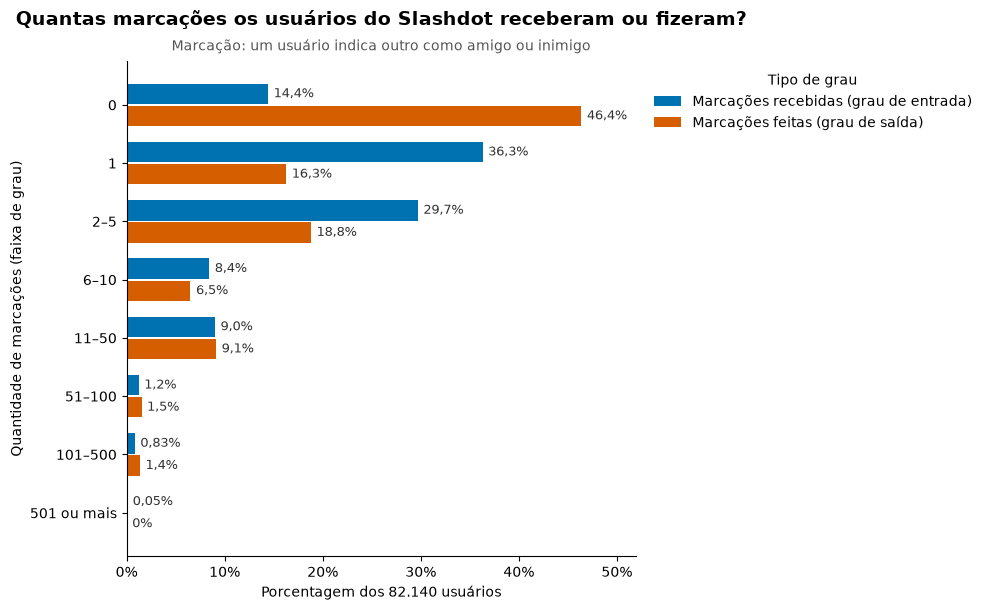

In [13]:
# [IA] Claude – código do gráfico de barras agrupadas por faixa de grau (pd.cut, barh, rótulos, savefig)
import matplotlib.pyplot as plt
import numpy as np

# faixas de grau: cada intervalo vai de (limite anterior, limite] -> 0, 1, 2-5, 6-10, ...
limites = [-1, 0, 1, 5, 10, 50, 100, 500, np.inf]
nomes_faixas = ["0", "1", "2–5", "6–10", "11–50", "51–100", "101–500", "501 ou mais"]

series = [
    ("grau_entrada", "Marcações recebidas (grau de entrada)", "#0072B2"),
    ("grau_saida", "Marcações feitas (grau de saída)", "#D55E00"),
]

total_usuarios = len(graus)


def formatar_porcentagem(valor):
    # vírgula decimal; faixas raras ganham duas casas para não virar "0,0%"
    if valor == 0:
        return "0%"
    if valor < 0.01:
        return "<0,01%"
    casas = 1 if valor >= 1 else 2
    return f"{valor:.{casas}f}%".replace(".", ",")


fig, ax = plt.subplots(figsize=(10, 6.2), facecolor="white")

posicoes = np.arange(len(nomes_faixas))
altura = 0.38
maior_porcentagem = 0

for deslocamento, (coluna, rotulo, cor) in zip([-altura / 2, altura / 2], series):
    contagem = (
        pd.cut(graus[coluna], bins=limites, labels=nomes_faixas)
        .value_counts()
        .reindex(nomes_faixas, fill_value=0)
    )
    porcentagem = contagem / total_usuarios * 100
    maior_porcentagem = max(maior_porcentagem, porcentagem.max())

    # altura um pouco menor que o espaço reservado: deixa uma fresta branca entre as duas barras
    barras = ax.barh(posicoes + deslocamento, porcentagem, height=altura * 0.92,
                     color=cor, label=rotulo)
    ax.bar_label(barras, labels=[formatar_porcentagem(p) for p in porcentagem],
                 padding=4, fontsize=9.5, color="#333333")

ax.set_yticks(posicoes, nomes_faixas)
ax.invert_yaxis()  # faixa 0 no topo
ax.set_xlim(0, maior_porcentagem * 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")

total_texto = f"{total_usuarios:,}".replace(",", ".")
ax.set_xlabel(f"Porcentagem dos {total_texto} usuários")
ax.set_ylabel("Quantidade de marcações (faixa de grau)")
ax.set_title(
    "Quantas marcações os usuários do Slashdot receberam ou fizeram?",
    fontsize=14, fontweight="bold", pad=26,
)
ax.text(0.5, 1.015, "Marcação: um usuário indica outro como amigo ou inimigo",
        transform=ax.transAxes, fontsize=10, color="#555555", ha="center", va="bottom")

ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.legend(title="Tipo de grau", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

fig.tight_layout()

pasta_figuras = pasta_projeto / "out" / "parte2"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "distribuicao_graus.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()

**Nota analítica**

**O que está sendo mostrado.** O gráfico compara, em cada faixa de grau, a porcentagem dos 82.140 usuários do Slashdot que receberam aquela quantidade de marcações (azul) e a porcentagem que fizeram aquela quantidade (laranja).

**Insight.** A diferença é especialmente clara na faixa zero. Quase metade dos usuários (46,4%) não fez nenhuma marcação, enquanto 14,4% não receberam nenhuma. No outro extremo, alguns usuários receberam 501 marcações ou mais. Nenhum usuário fez tantas marcações: o maior grau de saída foi 428.

**Por que este tipo de visualização.** As barras lado a lado facilitam a comparação entre marcações recebidas e feitas dentro de cada faixa. Usamos faixas mais estreitas nos graus baixos, onde se concentra a maioria dos usuários, e mais amplas nos graus altos, onde há poucos casos. Como as faixas têm larguras diferentes, cada barra deve ser lida como a porcentagem de usuários no intervalo inteiro. Por exemplo, a barra de 101 a 500 reúne todos os usuários nessa faixa, mesmo que alguns graus específicos sejam raros.

### 5.5 Concentração das marcações negativas

Visualização exploratória 2. Na seção anterior, vimos como os graus de entrada e de saída se distribuem. Aqui queremos saber se uma pequena parcela dos usuários concentra boa parte das marcações de inimigo. Para isso, fazemos duas listas: uma com quem mais marcou outras pessoas como inimigas e outra com quem mais recebeu esse tipo de marcação.

Em cada lista, começamos pelos usuários com mais marcações e vamos somando seus totais. A tabela mostra quanto do total os primeiros 1%, os primeiros 10% e todos os usuários acumulam. O gráfico mostra a mesma soma à medida que incluímos mais pessoas. No eixo X, 100% corresponde aos 82.140 usuários. No eixo Y, 100% corresponde às 124.130 marcações de inimigo.

In [14]:
# [IA] ChatGPT - apoio na soma acumulada das marcações negativas
total_usuarios = len(graus)
negativas_feitas = graus["saida_neg"].sort_values(ascending=False)
negativas_recebidas = graus["entrada_neg"].sort_values(ascending=False)
total_negativas = negativas_feitas.sum()

acumulado_feitas = negativas_feitas.cumsum().reset_index(drop=True)
acumulado_recebidas = negativas_recebidas.cumsum().reset_index(drop=True)

linhas_concentracao = []
for corte in (1, 10, 100):
    quantidade = total_usuarios * corte // 100
    linhas_concentracao.append({
        "Usuários do topo (%)": corte,
        "Quantidade de usuários": quantidade,
        "Negativas feitas (%)": 100 * acumulado_feitas.iloc[quantidade - 1] / total_negativas,
        "Negativas recebidas (%)": 100 * acumulado_recebidas.iloc[quantidade - 1] / total_negativas,
    })

resumo_concentracao_negativas = pd.DataFrame(linhas_concentracao).round(2)
resumo_concentracao_negativas

,Usuários do topo (%),Quantidade de usuários,Negativas feitas (%),Negativas recebidas (%)
0,1,821,53.66,36.11
1,10,8214,94.41,77.33
2,100,82140,100.00,100.00


**Interpretação da tabela**

Entre os 82.140 usuários, os 821 que mais fizeram marcações de inimigo (cerca de 1%) fizeram 53,66% do total. No ranking de quem recebeu, os 821 mais marcados como inimigos receberam 36,11%. Os dois rankings são calculados separadamente, então as pessoas do topo podem ser diferentes.

Quando ampliamos cada grupo para 10% dos usuários, os percentuais chegam a 94,41% das negativas feitas e 77,33% das recebidas. Nos dois cortes, as marcações ficaram mais concentradas em quem fez do que em quem recebeu. A linha de 100% inclui todos os usuários e soma todas as 124.130 marcações em cada ranking.

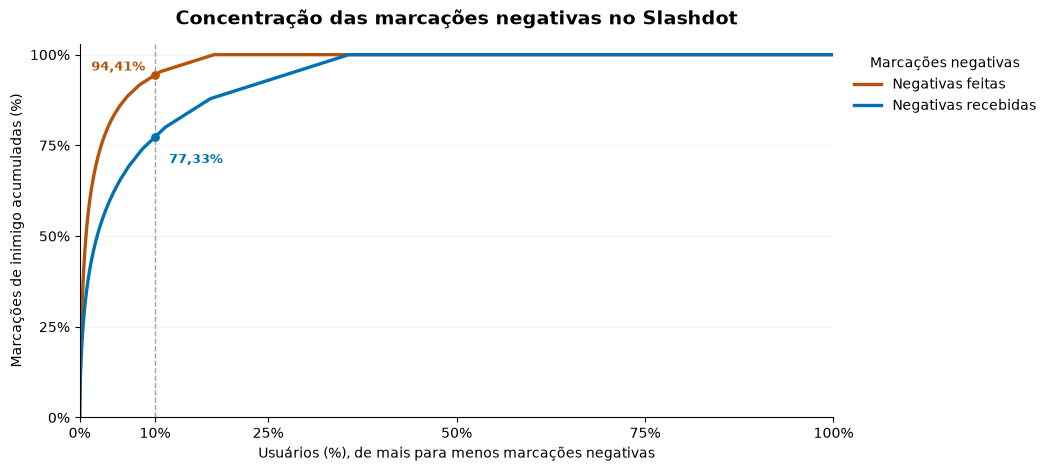

In [15]:
# [IA] ChatGPT - apoio na montagem da curva acumulada com Matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

percentual_usuarios = 100 * pd.RangeIndex(total_usuarios + 1) / total_usuarios
fig, eixo = plt.subplots(figsize=(10.4, 4.6), layout="constrained")
for acumulado, rotulo, cor in (
    (acumulado_feitas, "Negativas feitas", "#B45309"),
    (acumulado_recebidas, "Negativas recebidas", "#0072B2"),
):
    percentual_negativas = 100 * acumulado / total_negativas
    eixo.plot(percentual_usuarios, [0, *percentual_negativas], label=rotulo, color=cor, linewidth=2.4)

eixo.axvline(10, color="#94A3B8", linestyle="--", linewidth=1)
corte_10 = resumo_concentracao_negativas.loc[
    resumo_concentracao_negativas["Usuários do topo (%)"] == 10
].iloc[0]
for coluna, cor, deslocamento, horizontal, vertical in (
    ("Negativas feitas (%)", "#B45309", (-7, 1), "right", "bottom"),
    ("Negativas recebidas (%)", "#0072B2", (10, -12), "left", "top"),
):
    valor = corte_10[coluna]
    eixo.scatter(10, valor, color=cor, s=28, zorder=3)
    eixo.annotate(
        f"{valor:.2f}%".replace(".", ","), (10, valor),
        xytext=deslocamento, textcoords="offset points",
        color=cor, fontsize=9, fontweight="bold", ha=horizontal, va=vertical,
    )
eixo.set(xlim=(0, 100), ylim=(0, 103), xticks=[0, 10, 25, 50, 75, 100],
         yticks=[0, 25, 50, 75, 100])
eixo.xaxis.set_major_formatter(PercentFormatter(xmax=100))
eixo.yaxis.set_major_formatter(PercentFormatter(xmax=100))
eixo.set_xlabel("Usuários (%), de mais para menos marcações negativas")
eixo.set_ylabel("Marcações de inimigo acumuladas (%)")
eixo.set_title("Concentração das marcações negativas no Slashdot", fontsize=14, fontweight="bold", pad=14)
eixo.grid(axis="y", color="#EDF1F5", linewidth=0.6)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(title="Marcações negativas", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

pasta_figuras = pasta_projeto / "out" / "parte2"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "avd_concentracao_negativas.png", dpi=150, facecolor="white")
plt.show()

**Interpretação do gráfico**

A linha laranja soma as negativas feitas, começando por quem mais marcou outras pessoas como inimigas. A azul soma as negativas recebidas, começando por quem mais foi marcado como inimigo. Na linha tracejada de 10%, a laranja chega perto de 94% e a azul, de 77%. A laranja cresce mais depressa no início, mostrando que uma parcela menor dos usuários concentra boa parte das marcações feitas.

Ao avançar para a direita, incluímos os usuários com menos marcações negativas, até chegar a todos os 82.140. Quando uma curva atinge 100% das marcações, ela fica reta porque os usuários restantes têm zero naquele ranking e já não acrescentam nada à soma.

**Por que este tipo de gráfico**

Usamos uma curva acumulada porque ela mostra, de uma vez, quanto do total cada parcela dos usuários concentra: quanto mais rápido a linha sobe, mais concentradas estão as marcações. Uma linha para quem fez e outra para quem recebeu permitem comparar os dois rankings no mesmo eixo, e a linha tracejada de 10% marca o ponto citado na tabela.

## 6. Pilar relacional

### 6.1 Correlação entre marcações feitas e recebidas

A tabela calcula a correlação de Pearson entre as quatro contagens por usuário: marcações positivas e negativas feitas e recebidas. Os identificadores e os graus totais não entram no cálculo.

Os coeficientes variam de −1 a 1 e medem associação linear, não causalidade. Valores próximos de zero indicam pouca associação linear. Pearson é sensível a valores extremos. Colunas constantes produzem correlações indefinidas (`NaN`).

In [16]:
# [IA] ChatGPT - apoio no calculo da tabela de correlacoes com pandas
colunas_relacionais = ["saida_pos", "saida_neg", "entrada_pos", "entrada_neg"]

correlacoes_pearson = graus[colunas_relacionais].corr(method="pearson", min_periods=2)

correlacoes_pearson.round(3)

,saida_pos,saida_neg,entrada_pos,entrada_neg
saida_pos,1.000,0.302,0.311,0.216
saida_neg,0.302,1.000,0.099,0.211
entrada_pos,0.311,0.099,1.000,0.436
entrada_neg,0.216,0.211,0.436,1.000


**Interpretação**

Todos os pares têm correlação direta. Consideramos fraca abaixo de 0,3, moderada até 0,7 e forte acima disso. 
A mais forte é entre as marcações de amigo e de inimigo recebidas (r = 0,436). O mesmo padrão aparece, mais fraco, entre as marcações feitas (r = 0,302). Entre o que se faz e o que se recebe, só as marcações de amigo são moderadas (r = 0,311). As demais são fracas, e a mais fraca é marcar inimigos × ser marcado como amigo (r = 0,099).

Pearson mede só a parte linear. Com mediana 1 e máximo 2.512 de amigos recebidos (seção 5.3), os extremos podem distorcer o r e representar mal quem tem poucas marcações. São contagens por usuário: não mostram causa nem se as marcações foram retribuídas. A pergunta de pesquisa exige verificar, para cada marcação de A para B, a distância de volta de B até A conforme o sinal.

**Comparação com a correlação de Spearman**

O Spearman troca cada contagem pela posição do usuário no ranking (quem tem mais, quem tem menos) e calcula a correlação dessas posições. Assim, um usuário com milhares de marcações não pesa mais do que a sua posição, e o resultado depende menos dos valores extremos. A tabela coloca os dois coeficientes lado a lado para cada par de contagens.

In [17]:
import itertools

correlacoes_spearman = graus[colunas_relacionais].rank().corr()

comparacao_correlacoes = pd.DataFrame([
    {
        "Par de contagens": f"{primeira} × {segunda}",
        "Pearson": correlacoes_pearson.loc[primeira, segunda],
        "Spearman": correlacoes_spearman.loc[primeira, segunda],
    }
    for primeira, segunda in itertools.combinations(colunas_relacionais, 2)
])
comparacao_correlacoes["Diferença"] = comparacao_correlacoes["Spearman"] - comparacao_correlacoes["Pearson"]
comparacao_correlacoes.round(3)

,Par de contagens,Pearson,Spearman,Diferença
0,saida_pos × saida_neg,0.302,0.462,0.159
1,saida_pos × entrada_pos,0.311,0.188,-0.122
2,saida_pos × entrada_neg,0.216,0.089,-0.127
3,saida_neg × entrada_pos,0.099,0.236,0.137
4,saida_neg × entrada_neg,0.211,0.266,0.055
5,entrada_pos × entrada_neg,0.436,0.276,-0.160


**Interpretação**

Os dois coeficientes são positivos em todos os pares, mas alguns mudam bastante. Entre as marcações feitas, a relação entre amigos e inimigos marcados sobe de 0,302 no Pearson para 0,462 no Spearman: quem marca mais amigos tende a ficar mais alto também no ranking de inimigos marcados. Entre as recebidas, a relação cai de 0,436 para 0,276, sinal de que parte da força vista no Pearson vinha de poucos usuários muito marcados.

Entre fazer e receber, o Spearman fica fraco em todos os pares: o maior valor é 0,266 (inimigos marcados × marcado como inimigo) e o menor é 0,089 (amigos marcados × marcado como inimigo). Pela régua usada acima, só o par de marcações feitas é moderado no Spearman. Todos os outros são fracos.

### 6.2 Marcações recebidas e feitas por usuário

Visualização exploratória 3. Para cada usuário, comparamos quantas marcações ele recebeu com quantas fez. Cada barra mostra a porcentagem dos 82.140 usuários em um de três grupos: recebeu mais do que fez, recebeu e fez a mesma quantidade, ou fez mais do que recebeu. A barra azul destaca o maior grupo. O gráfico da seção 5.4 já mostrava quantos usuários nunca fizeram ou nunca receberam marcações; aqui a novidade é comparar, para cada usuário, o que ele recebeu com o que fez.

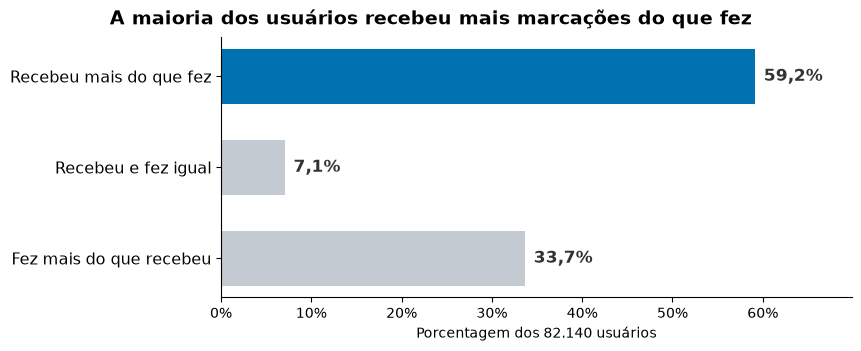

In [18]:
import matplotlib.pyplot as plt
import numpy as np

recebidas = graus["grau_entrada"]
feitas = graus["grau_saida"]
total_usuarios = len(graus)
nomes = ["Recebeu mais do que fez", "Recebeu e fez igual", "Fez mais do que recebeu"]
filtros = [recebidas.gt(feitas), recebidas.eq(feitas), feitas.gt(recebidas)]
porcentagens = [100 * filtro.sum() / total_usuarios for filtro in filtros]
cores = ["#0072B2", "#C4CAD2", "#C4CAD2"]

fig, eixo = plt.subplots(figsize=(8.5, 3.4), layout="constrained")
posicoes = np.arange(len(nomes))
barras = eixo.barh(posicoes, porcentagens, color=cores, height=0.6)
eixo.bar_label(barras, labels=[f"{p:.1f}%".replace(".", ",") for p in porcentagens],
               padding=6, fontsize=12, fontweight="bold", color="#333333")
eixo.set_yticks(posicoes, nomes, fontsize=11.5)
eixo.invert_yaxis()
eixo.set_xlim(0, max(porcentagens) * 1.18)
eixo.xaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")
eixo.set_xlabel(f"Porcentagem dos {total_usuarios:,} usuários".replace(",", "."))
fig.suptitle("A maioria dos usuários recebeu mais marcações do que fez", fontsize=14, fontweight="bold")
eixo.spines[["top", "right"]].set_visible(False)
eixo.set_axisbelow(True)

fig.savefig(pasta_projeto / "out" / "parte2" / "avd_recebidas_feitas.png", dpi=150, facecolor="white")
plt.show()

**Interpretação**

A maioria dos usuários (59,2%) recebeu mais marcações do que fez, enquanto 33,7% fizeram mais do que receberam. Apenas 7,1% receberam e fizeram a mesma quantidade.

O grupo que recebeu mais é grande principalmente por causa de quem nunca marcou ninguém: são 46,4% dos usuários, os mesmos da faixa zero de marcações feitas na seção 5.4. Do outro lado, 14,4% só fizeram marcações e nunca foram marcados. A rede tem, portanto, muito mais usuários que são apenas marcados do que usuários que apenas marcam.

**Por que este tipo de gráfico**

Usamos barras horizontais porque são três grupos com nomes longos, que ficam legíveis à esquerda, e o comprimento das barras é fácil de comparar. Todas as barras ficam em cinza e só a do maior grupo em azul, para o olho ir direto à mensagem do título; como há uma única série, os nomes das barras fazem o papel de legenda.

## 7. Investigação de outliers

Nesta seção, usamos o intervalo interquartil (IQR) para identificar graus altos e o boxplot para comparar os extremos das marcações recebidas e feitas. Em seguida, examinamos os usuários que mais receberam ou fizeram marcações e contamos quantos fizeram cada quantidade entre 180 e 220. Essas análises ajudam a decidir se há motivo para tratar algum registro como erro.

### 7.1 Detecção pelo intervalo interquartil (IQR)

O IQR mede a largura da faixa que contém os 50% centrais dos graus. Para calcular o limite superior, somamos uma vez e meia essa largura ao terceiro quartil. Para o inferior, subtraímos a mesma quantidade do primeiro quartil. Aplicamos a regra separadamente às marcações recebidas e às feitas.

In [19]:
# [IA] ChatGPT - apoio no calculo dos limites e sinalizacoes por IQR
colunas_outliers = ["grau_entrada", "grau_saida"]
q1 = graus[colunas_outliers].quantile(0.25)
q3 = graus[colunas_outliers].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

sinalizacoes = (
    graus[colunas_outliers].lt(limite_inferior)
    | graus[colunas_outliers].gt(limite_superior)
)

resumo_outliers = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "limite_inferior": limite_inferior,
    "limite_superior": limite_superior,
    "usuarios_sinalizados": sinalizacoes.sum(),
    "usuarios_sinalizados (%)": sinalizacoes.mean() * 100,
})
resumo_outliers.round(2)

,Q1,Q3,IQR,limite_inferior,limite_superior,usuarios_sinalizados,usuarios_sinalizados (%)
grau_entrada,1.0,4.0,3.0,-3.5,8.5,11069,13.48
grau_saida,0.0,3.0,3.0,-4.5,7.5,12557,15.29


**Interpretação**

O primeiro grau sinalizado é 9 na entrada e 8 na saída. O critério sinalizou 13,48% dos usuários na entrada e 15,29% na saída. Como os graus começam em zero e os dois limites inferiores são negativos, todos os casos sinalizados estão acima do limite superior. A regra mostra onde essa faixa começa, e o boxplot ajuda a ver até onde ela vai.

**A mesma regra em escala logarítmica**

Como poucos usuários têm graus muito altos, a regra aplicada aos valores originais sinaliza muita gente. Repetimos o cálculo depois de transformar cada grau com log(1 + grau), que aproxima os valores grandes e mantém o zero. Depois, convertemos o limite de volta para número de marcações.

In [20]:
import numpy as np

graus_log = np.log1p(graus[colunas_outliers])
q1_log = graus_log.quantile(0.25)
q3_log = graus_log.quantile(0.75)
limite_superior_log = q3_log + 1.5 * (q3_log - q1_log)
# [IA] Claude – correção do arredondamento: o limite volta para número de marcações e é arredondado antes da comparação
limite_log_em_marcacoes = np.expm1(limite_superior_log).round(9)
sinalizacoes_log = graus[colunas_outliers].gt(limite_log_em_marcacoes)

pd.DataFrame({
    "limite na escala original": limite_superior,
    "limite na escala log (em marcações)": limite_log_em_marcacoes,
    "sinalizados na escala original (%)": sinalizacoes.mean() * 100,
    "sinalizados na escala log (%)": sinalizacoes_log.mean() * 100,
    "primeiro grau sinalizado na escala log": pd.Series(
        [graus.loc[sinalizacoes_log[coluna], coluna].min() for coluna in colunas_outliers],
        index=colunas_outliers,
    ),
}).round(2)

,limite na escala original,limite na escala log (em marcações),sinalizados na escala original (%),sinalizados na escala log (%),primeiro grau sinalizado na escala log
grau_entrada,8.5,18.76,13.48,6.44,19
grau_saida,7.5,31.00,15.29,4.69,32


**Interpretação**

Na escala log, o limite sobe de 8,5 para 18,8 marcações recebidas e de 7,5 para 31 marcações feitas. Com isso, a parcela de usuários sinalizados cai de 13,48% para 6,44% na entrada e de 15,29% para 4,69% na saída. O primeiro grau sinalizado passa a ser 19 na entrada e 32 na saída.

A escala log combina melhor com dados em que a maioria tem poucas marcações e poucos têm muitas, porque separa os casos realmente extremos. Mesmo assim, a regra só aponta valores altos. Ela não mostra que algum registro esteja errado, por isso a decisão da seção 7.6 continua valendo.

### 7.2 Visualização dos graus em boxplots

Visualização exploratória 4. Na seção 7.1, identificamos quantidades de marcações que ficaram acima da faixa típica. Aqui usamos o boxplot para comparar, lado a lado, as marcações que os usuários receberam e as que fizeram. Cada caixa mostra onde está a metade central dos valores, e a linha escura marca a mediana. Os pontos vermelhos destacam os graus altos sinalizados pela regra do IQR na escala original, a primeira tabela da seção 7.1. Um mesmo valor pode corresponder a vários usuários.

A partir de 1, cada marca do eixo Y representa dez vezes a anterior: $10^0$ vale 1, $10^1$ vale 10 e $10^2$ vale 100. Entre 0 e 1, a escala é linear para incluir o zero. Assim, os graus baixos e os mais altos ficam visíveis no mesmo gráfico.

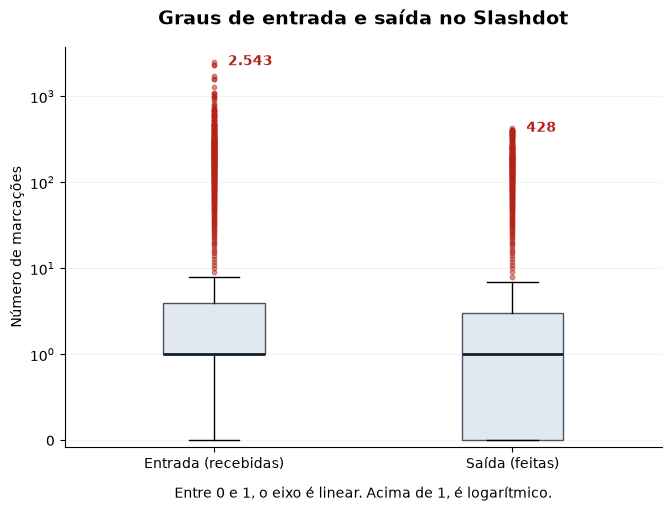

In [21]:
# [IA] ChatGPT - apoio na configuracao do boxplot e da escala do eixo
import matplotlib.pyplot as plt

colunas = ["grau_entrada", "grau_saida"]
fig, eixo = plt.subplots(figsize=(6.6, 5), layout="constrained")
caixas = eixo.boxplot(
    [graus[coluna] for coluna in colunas],
    whis=1.5,
    widths=0.34,
    patch_artist=True,
    showfliers=False,
    boxprops={"facecolor": "#E2E8F0", "edgecolor": "#475569"},
    medianprops={"color": "#17212B", "linewidth": 2},
)

for posicao, coluna in enumerate(colunas, start=1):
    valores = graus.loc[sinalizacoes[coluna], coluna].unique()
    eixo.scatter(
        [posicao] * len(valores), valores, color="#B42318", s=10, alpha=0.48,
    )
    maximo = graus[coluna].max()
    eixo.annotate(
        f"{maximo:,}".replace(",", "."),
        (posicao, maximo),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        color="#B42318",
        fontweight="bold",
    )

eixo.set_xticks([1, 2], ["Entrada (recebidas)", "Saída (feitas)"])
eixo.set_yscale("symlog", linthresh=1, linscale=0.9)
eixo.set_ylim(-0.08, 3800)
eixo.set_yticks([0, 1, 10, 100, 1000], ["0", "$10^{0}$", "$10^{1}$", "$10^{2}$", "$10^{3}$"])
eixo.set_ylabel("Número de marcações")
eixo.set_xlabel("Entre 0 e 1, o eixo é linear. Acima de 1, é logarítmico.", labelpad=11, fontsize=10, color="black")
eixo.set_title("Graus de entrada e saída no Slashdot", pad=16, fontsize=14, fontweight="bold")
eixo.set_axisbelow(True)
eixo.grid(axis="y", color="#EDF1F5", linewidth=0.6)
eixo.spines[["top", "right"]].set_visible(False)
pasta_figuras = pasta_projeto / "out" / "parte2"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "avd_boxplot_graus.png", dpi=150, facecolor="white")
plt.show()

**Interpretação**

A mediana é de 1 marcação nos dois lados. Isso quer dizer que pelo menos metade dos usuários recebeu no máximo uma marcação. Olhando separadamente para as marcações feitas, pelo menos metade fez no máximo uma.

A maior diferença aparece nos extremos. O maior grau de entrada foi de 2.543 marcações recebidas, enquanto o maior grau de saída foi de 428 feitas.

**Por que este tipo de gráfico**

O boxplot resume cada distribuição em mediana, quartis e extremos, o que permite comparar entrada e saída lado a lado num espaço pequeno. A escala logarítmica acima de 1 foi usada porque os graus vão de 0 a 2.543: em escala linear, as caixas ficariam espremidas perto do zero.

### 7.3 Usuários que mais receberam marcações

O boxplot mostrou que os maiores graus aparecem na entrada. A centralidade de grau de entrada mede quantas marcações cada usuário recebeu. Para examinar os valores mais altos, ordenamos os usuários por esse total, mostramos os dez primeiros e colocamos ao lado quantas marcações cada um fez.

In [22]:
# [IA] ChatGPT - apoio na ordenacao e apresentacao dos graus
maiores_entradas = (
    graus[["grau_entrada", "grau_saida"]]
    .sort_values("grau_entrada", ascending=False, kind="stable")
    .head(10)
)
maiores_entradas

,grau_entrada,grau_saida
usuario,,
80,2543,14
47,2344,14
636,2290,0
41,1727,0
760,1608,160
191,1591,400
660,1270,0
1293,1110,160
770,1102,0


**Interpretação**

Os dez usuários da tabela receberam entre 1.050 e 2.543 marcações. O primeiro recebeu 2.543 e fez 14. O terceiro recebeu 2.290 e fez zero. Esses exemplos mostram como os dois graus podem ser bem diferentes para a mesma pessoa.

### 7.4 Usuários que mais fizeram marcações

A centralidade de grau de saída mede quantas marcações cada usuário fez. Usamos as mesmas duas colunas da tabela anterior, agora ordenadas pelo total feito. Assim podemos comparar os maiores graus de saída com os de entrada e ver se os mesmos usuários aparecem nas duas listas.

In [23]:
# [IA] ChatGPT - apoio na ordenacao e apresentacao dos graus
maiores_saidas = (
    graus[["grau_saida", "grau_entrada"]]
    .sort_values("grau_saida", ascending=False, kind="stable")
    .head(10)
)
maiores_saidas

,grau_saida,grau_entrada
usuario,,
8895,428,55
9235,405,75
667,403,65
869,402,69
1111,402,316
1635,402,347
3245,402,30
4956,402,135
5174,402,21


**Interpretação**

Os dez maiores graus de saída vão de 402 a 428. É uma faixa bem mais estreita que a da entrada, que vai de 1.050 a 2.543. O usuário que lidera a saída fez 428 marcações e recebeu 55. As duas listas trazem usuários diferentes, o que ajuda a separar quem mais faz marcações de quem mais recebe.

### 7.5 Frequências próximas do grau de saída 200

Na seção 5.4, uma única barra reúne os usuários que fizeram de 101 a 500 marcações. Para entender o que acontece dentro dessa faixa, contamos quantos usuários têm cada grau de saída e listamos os cinco graus mais frequentes.

In [24]:
# [IA] ChatGPT - apoio na contagem dos graus de saída mais frequentes
grau_saida = graus["grau_saida"]
graus_na_faixa = grau_saida[grau_saida.between(101, 500)]

top_5_graus = (
    graus_na_faixa.value_counts()
    .nlargest(5)
    .rename_axis("grau_saida")
    .to_frame("usuarios")
)
top_5_graus

,usuarios
grau_saida,
201,109
202,88
203,38
200,27
110,16


Os quatro graus de saída mais frequentes nessa faixa foram 201, 202, 203 e 200, nessa ordem. Como os quatro valores ficam próximos de 200, examinamos o intervalo de 180 a 220 para comparar suas contagens com as dos graus vizinhos.

In [25]:
# [IA] ChatGPT - apoio na contagem das frequencias proximas do grau 200
grau_referencia = 200
margem = 20
faixa_graus = range(grau_referencia - margem, grau_referencia + margem + 1)

frequencias_proximas_200 = (
    graus["grau_saida"].value_counts()
    .reindex(faixa_graus, fill_value=0)
    .rename_axis("grau_saida")
    .to_frame("usuarios")
)
frequencias_proximas_200

,usuarios
grau_saida,
180,1
181,4
182,3
183,3
184,10
185,8
186,10
187,7
188,6


**Interpretação**

Entre os graus de saída de 180 a 220, as maiores contagens ocorreram em 201 e 202 marcações, com 109 e 88 usuários, respectivamente. Para comparação, 12 usuários fizeram exatamente 199 marcações e 9 fizeram 204. A tabela mostra uma concentração local em 201 e 202. A causa dessa concentração permanece em aberto.

**Frequências próximas do grau de saída 400**

A seção 7.4 mostrou que vários dos maiores graus de saída ficam em 402 ou perto disso. Repetimos a contagem da tabela anterior para o intervalo de 380 até 428, o maior grau de saída, mostrando apenas os graus com pelo menos um usuário.

In [26]:
frequencias_proximas_400 = (
    graus["grau_saida"].value_counts()
    .reindex(range(380, graus["grau_saida"].max() + 1), fill_value=0)
    .loc[lambda contagem: contagem > 0]
    .rename_axis("grau_saida")
    .to_frame("usuarios")
)
frequencias_proximas_400

,usuarios
grau_saida,
386,1
387,1
394,1
397,1
399,2
400,4
401,5
402,7
403,1


**Interpretação**

Entre 380 e 428 marcações feitas, há 25 usuários. Desses, 18 fizeram entre 400 e 405 marcações, com o maior grupo em 402 (7 usuários). Acima de 405, aparece apenas um usuário, com 428.

Assim, as marcações feitas se acumulam perto de 200 (tabela anterior) e perto de 400, e quase ninguém passa desse segundo ponto. O dataset não informa por que isso acontece, então registramos o padrão sem atribuir uma causa e mantemos esses usuários na análise.

### 7.6 Decisão de tratamento

O IQR, nas escalas original e logarítmica, apontou onde começam os graus altos, os rankings mostraram até onde eles chegam e as tabelas de frequências localizaram um pico em 201 e 202 e um segundo acúmulo entre 400 e 405. Essas três observações ajudam a entender partes diferentes da distribuição.

Mantemos as marcações no dataset. Para corrigir ou remover um registro, precisaríamos de evidência de um erro específico, como uma marcação inválida. Remover usuários ou marcações com base só no grau alteraria as contagens e poderia mudar os caminhos da rede.

**Graus sinalizados pelo IQR (7.1 e 7.2).** São outliers estatísticos: com 8, 9 e 10 marcações feitas, há 1.085, 877 e 725 usuários, e a frequência cai aos poucos. Mantemos os valores.

**Maiores graus (7.3 e 7.4).** São outliers estatísticos: o usuário **80** recebeu 2.543 marcações e o **8895** fez 428. São valores raros, e as verificações da seção 4 não apontaram erro nesses registros. Mantemos os dois.

**Picos na saída (7.5).** São um padrão estatístico de causa desconhecida: há 109 usuários com grau 201, 88 com grau 202 e 18 entre 400 e 405. O projeto mostra essa concentração, mas não confirma uma regra do site que a explique. Mantemos as marcações.

## 8. Retorno das marcações de amigo e inimigo

Nas seções anteriores, analisamos quantas marcações os usuários fizeram e receberam. Agora partimos de marcações individuais. Se Ana marcou Bruno, começamos em Bruno e seguimos as setas da rede para ver se existe um caminho de volta até Ana. Cada seta percorrida na volta vale um passo.

A tabela compara 1.000 marcações de amigo e 1.000 de inimigo. Para calcular a porcentagem com volta, usamos as 1.000 marcações de cada grupo. Para calcular a mediana de passos, usamos apenas as que tiveram volta. Os resultados vêm de `out/parte2/passos_volta.csv`, gerado no [notebook de algoritmos](02_grafos_algoritmos.ipynb). No arquivo, `passos_volta` fica vazio quando a busca não encontra caminho de volta. Esse vazio não é um dado faltante, e sim um resultado da busca. Por isso essas marcações não são apagadas e aparecem como "sem volta" nas porcentagens e no gráfico da seção 8.2.

In [27]:
# [IA] ChatGPT - apoio no resumo das voltas por tipo de marcação
caminho_csv = pasta_projeto / "out" / "parte2" / "passos_volta.csv"
voltas = pd.read_csv(caminho_csv)

resumo_voltas = voltas.groupby("tipo", sort=False).agg(
    marcacoes=("tipo", "size"),
    com_volta=("passos_volta", "count"),
    mediana_passos=("passos_volta", "median"),
)
resumo_voltas["percentual_com_volta"] = (
    100 * resumo_voltas["com_volta"] / resumo_voltas["marcacoes"]
).round(1)

resumo_voltas = resumo_voltas.reset_index()
resumo_voltas["tipo"] = resumo_voltas["tipo"].str.capitalize()
resumo_voltas["mediana_passos"] = resumo_voltas["mediana_passos"].astype("Float64")
resumo_voltas = resumo_voltas.rename(columns={
    "tipo": "Tipo de marcação",
    "marcacoes": "Marcações analisadas",
    "com_volta": "Com caminho de volta",
    "percentual_com_volta": "Com caminho de volta (%)",
    "mediana_passos": "Mediana de passos",
})
resumo_voltas[[
    "Tipo de marcação", "Marcações analisadas", "Com caminho de volta",
    "Com caminho de volta (%)", "Mediana de passos",
]]

,Tipo de marcação,Marcações analisadas,Com caminho de volta,Com caminho de volta (%),Mediana de passos
0,Amigo,1000,622,62.2,3.0
1,Inimigo,1000,669,66.9,3.0


**Interpretação**

Entre as 1.000 marcações de amigo, 622 tiveram caminho de volta (62,2%). Entre as 1.000 de inimigo, 669 tiveram volta (66,9%). Nesta amostra, encontramos volta em 47 casos a mais no grupo de inimigo, uma diferença de 4,7 pontos percentuais.

Entre as marcações que tiveram caminho de volta, a mediana foi de 3 passos nos dois grupos. Isso mostra que o valor do meio foi igual. Para saber se os grupos têm a mesma proporção de voltas curtas ou longas, precisamos olhar a distribuição dos passos.

### 8.1 Distribuição dos passos de volta

Na tabela anterior, vimos que a mediana foi de 3 passos nos dois grupos. Agora contamos quantas voltas tiveram cada tamanho, de 1 a 7 passos. Imagine que Ana marcou Bruno como amigo. Se Bruno marcou Ana de volta, foi 1 passo. Se o caminho mais curto foi de Bruno para Carla e de Carla para Ana, foram 2 passos. Contamos as setas a partir de Bruno. O grupo amigo ou inimigo vem da marcação original, de Ana para Bruno.

Cada linha da tabela corresponde a um número de passos. Na linha 1, por exemplo, o grupo amigo tem 225 voltas diretas. Isso representa 36,2% das 622 marcações de amigo que tiveram volta. No grupo inimigo, são 98 voltas diretas, ou 14,6% das 669 que tiveram volta. As marcações sem caminho de volta ficam fora desta tabela.

In [28]:
# [IA] ChatGPT - apoio no resumo da distribuição dos passos com pandas
voltas_encontradas = voltas.dropna(subset=["passos_volta"])
contagem_passos = pd.crosstab(
    voltas_encontradas["passos_volta"].astype(int),
    voltas_encontradas["tipo"],
).rename_axis(index="Passos", columns=None)

percentuais_passos = (100 * contagem_passos / contagem_passos.sum()).round(1)
distribuicao_passos = pd.DataFrame({
    "Amigo (quantidade)": contagem_passos["amigo"],
    "Amigo (%)": percentuais_passos["amigo"],
    "Inimigo (quantidade)": contagem_passos["inimigo"],
    "Inimigo (%)": percentuais_passos["inimigo"],
})
distribuicao_passos

,Amigo (quantidade),Amigo (%),Inimigo (quantidade),Inimigo (%)
Passos,,,,
1,225,36.2,98,14.6
2,65,10.5,76,11.4
3,150,24.1,248,37.1
4,132,21.2,173,25.9
5,38,6.1,60,9.0
6,11,1.8,12,1.8
7,1,0.2,2,0.3


**Interpretação**

As voltas de 1 passo foram mais frequentes entre as marcações de amigo: 225 de 622 (36,2%), contra 98 de 669 (14,6%) nas de inimigo. Em outras palavras, de cada 100 voltas encontradas, cerca de 36 foram diretas no grupo de amigo e 15 no de inimigo.

Já as voltas de 3 passos apareceram em 24,1% dos casos de amigo e 37,1% dos de inimigo. Os dois grupos têm a mesma mediana, mas a distribuição mostra que o tamanho das voltas aparece com frequências diferentes na amostra.

### 8.2 Como as marcações voltam

Visualização explanatória 1, que responde à pergunta de pesquisa. Na seção anterior, contamos os passos entre as marcações que tiveram volta. Aqui comparamos os dois grupos considerando as 1.000 marcações de cada um, inclusive as que ficaram sem volta. Em cada par de barras, a primeira representa as marcações de amigo e a segunda, as de inimigo.

Leia os pares da esquerda para a direita. A categoria “1 passo” mostra quem recebeu a marcação e marcou de volta diretamente. A categoria “3 passos” mostra os casos em que o caminho mais curto de volta teve exatamente três setas. À direita, os casos sem volta aparecem em dois pares: no primeiro, quem recebeu a marcação fez marcações na rede, mas nenhum caminho chegou a quem marcou. No segundo, quem recebeu nunca marcou ninguém, então a volta nem pode começar.

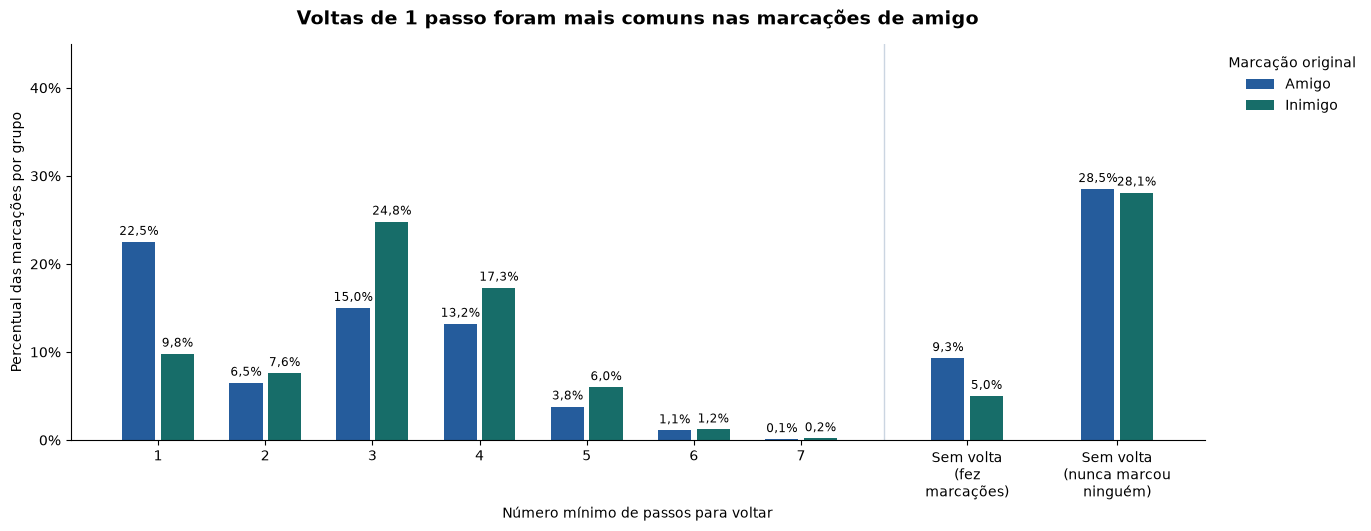

In [29]:
# [IA] ChatGPT - apoio na criação do gráfico de barras por número de passos
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

passos = voltas["passos_volta"].fillna(0).astype(int)
destino_sem_saida = voltas["destino"].map(graus["grau_saida"]).eq(0)
passos = passos.mask(passos.eq(0) & destino_sem_saida, -1)
contagem_voltas = pd.crosstab(passos, voltas["tipo"])
ordem_passos = sorted(contagem_voltas.index.drop([0, -1])) + [0, -1]
contagem_voltas = contagem_voltas.loc[ordem_passos, ["amigo", "inimigo"]]
percentuais_volta = contagem_voltas.div(contagem_voltas.sum()).mul(100)

posicoes = list(range(len(ordem_passos)))
posicoes[-2] += 0.55
posicoes[-1] += 0.95
rotulos_passos = [str(passo) for passo in ordem_passos[:-2]] + [
    "Sem volta\n(fez\nmarcações)", "Sem volta\n(nunca marcou\nninguém)",
]
largura = 0.36

fig, eixo = plt.subplots(figsize=(13.6, 5.2), layout="constrained")
for tipo, cor, deslocamento in [
    ("amigo", "#255C9C", -largura / 2),
    ("inimigo", "#176D69", largura / 2),
]:
    valores = percentuais_volta[tipo]
    barras = eixo.bar(
        [posicao + deslocamento for posicao in posicoes],
        valores, width=largura - 0.05, color=cor, label=tipo.capitalize(),
    )
    rotulos = [f"{valor:.1f}%".replace(".", ",") for valor in valores]
    eixo.bar_label(barras, labels=rotulos, padding=3, fontsize=8.5)

eixo.axvline((posicoes[-3] + posicoes[-2]) / 2, color="#CBD5E1", linewidth=1)
eixo.set_xticks(posicoes, rotulos_passos)
eixo.set(xlabel="Número mínimo de passos para voltar",
         ylabel="Percentual das marcações por grupo", ylim=(0, 45))
eixo.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
eixo.set_yticks(range(0, 41, 10))
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(title="Marcação original", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
eixo.set_title("Voltas de 1 passo foram mais comuns nas marcações de amigo", fontsize=14, fontweight="bold", pad=14)

fig.savefig(pasta_projeto / "out" / "parte2" / "avd_caminhos_de_volta.png",
            dpi=150, facecolor="white")
plt.show()

**Interpretação**

Na amostra, 22,5% das marcações de amigo tiveram volta direta, contra 9,8% das de inimigo. Em três passos, a ordem se inverteu: 24,8% das marcações de inimigo voltaram com essa distância, contra 15,0% das de amigo. Assim, mesmo com mediana de três passos nos dois grupos entre as voltas encontradas, os caminhos de um e de três passos tiveram frequências diferentes.

Ao todo, 37,8% das marcações de amigo e 33,1% das de inimigo ficaram sem volta, mas a maior parte desses casos não depende do tipo de marcação: em 28,5% e 28,1%, respectivamente, quem recebeu nunca marcou ninguém. Os casos sem volta em que quem recebeu tinha feito marcações somaram 9,3% das marcações de amigo e 5,0% das de inimigo.

**Por que este tipo de gráfico**

Usamos barras agrupadas porque a pergunta compara dois grupos, amigo e inimigo, em cada número de passos, e barras lado a lado deixam essa comparação direta. As porcentagens são calculadas sobre as 1.000 marcações de cada grupo, para que os dois tenham a mesma base, e os casos sem volta ficam separados à direita porque não são um número de passos.

## 9. Retorno por tipo de marcação e grau de saída

Na seção anterior, comparamos a quantidade de passos das voltas entre marcações de amigo e de inimigo. Agora também queremos saber se os resultados mudam conforme a quantidade de marcações feitas por quem recebeu a marcação original. Se Ana marcou Bruno, usamos as marcações feitas por Bruno, porque é nele que a volta começa.

Separamos os graus de saída em quatro faixas: 0, 1 a 3, 4 a 10 e 11 ou mais. Para cada faixa e tipo de marcação, mostramos o tamanho do grupo, a porcentagem com volta e a mediana de passos entre os casos com volta. As faixas organizam a comparação e cada linha pode ter um número diferente de marcações.

In [30]:
# [IA] ChatGPT - apoio no cruzamento da amostra com os graus dos usuários
voltas_com_grau = voltas.copy()
voltas_com_grau["grau_saida_destino"] = voltas_com_grau["destino"].map(graus["grau_saida"])
assert voltas_com_grau["grau_saida_destino"].notna().all()

voltas_com_grau["faixa_grau_saida"] = pd.cut(
    voltas_com_grau["grau_saida_destino"],
    bins=[-1, 0, 3, 10, float("inf")],
    labels=["0", "1 a 3", "4 a 10", "11 ou mais"],
)

resumo_por_grau = voltas_com_grau.groupby(
    ["faixa_grau_saida", "tipo"], observed=True
).agg(
    marcacoes=("passos_volta", "size"),
    com_volta=("passos_volta", "count"),
    mediana_passos=("passos_volta", "median"),
).reset_index()

resumo_por_grau["com_volta_pct"] = (
    100 * resumo_por_grau["com_volta"] / resumo_por_grau["marcacoes"]
).round(1)
resumo_por_grau["tipo"] = resumo_por_grau["tipo"].str.capitalize()

tabela_por_grau = resumo_por_grau[[
    "faixa_grau_saida", "tipo", "marcacoes", "com_volta_pct", "mediana_passos",
]].rename(columns={
    "faixa_grau_saida": "Marcações feitas por quem recebeu",
    "tipo": "Tipo de marcação",
    "marcacoes": "Marcações analisadas",
    "com_volta_pct": "Com volta (%)",
    "mediana_passos": "Mediana de passos",
})

tabela_por_grau.assign(
    **{"Mediana de passos": tabela_por_grau["Mediana de passos"].astype("string").fillna("—")}
)

,Marcações feitas por quem recebeu,Tipo de marcação,Marcações analisadas,Com volta (%),Mediana de passos
0,0,Amigo,285,0.0,—
1,0,Inimigo,281,0.0,—
2,1 a 3,Amigo,159,70.4,4.0
3,1 a 3,Inimigo,162,79.6,4.0
4,4 a 10,Amigo,115,88.7,4.0
5,4 a 10,Inimigo,131,97.7,4.0
6,11 ou mais,Amigo,441,92.5,2.0
7,11 ou mais,Inimigo,426,96.7,3.0


### 9.1 Com que frequência a marcação tem volta?

Visualização explanatória 2. Imagine que Ana marcou Bruno como amigo. Primeiro, olhamos quantas marcações Bruno fez na rede. Se ele fez duas, o caso entra na faixa **1 a 3**, na barra azul. Depois verificamos se algum caminho de setas sai de Bruno e chega de volta a Ana.

Cada barra mostra a porcentagem de casos com volta naquela faixa. Na barra azul de **1 a 3**, por exemplo, 112 das 159 marcações de amigo tiveram volta, ou **70,4%**. A tabela acima mostra quantos casos entraram no cálculo de cada barra. A faixa **0** fica fora das barras: 566 marcações foram recebidas por quem nunca marcou ninguém e, sem uma primeira seta, não há como voltar. Esses casos continuam na tabela acima.

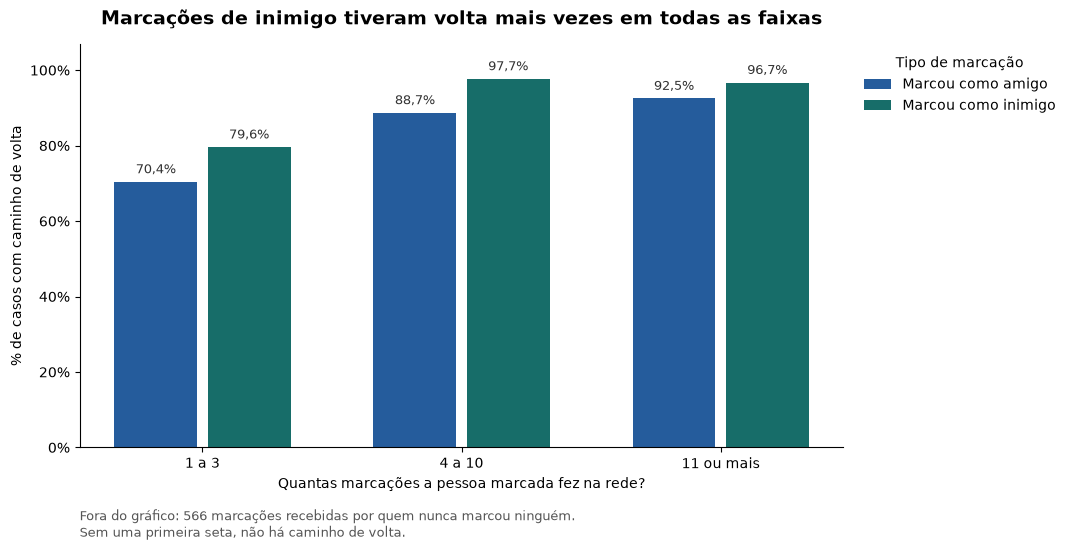

In [31]:
# [IA] ChatGPT - apoio na sintaxe do gráfico de barras por faixa de grau
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

faixas = resumo_por_grau["faixa_grau_saida"].cat.categories.tolist()[1:]
fora_do_grafico = resumo_por_grau.loc[
    resumo_por_grau["faixa_grau_saida"].eq("0"), "marcacoes"
].sum()
posicoes = range(len(faixas))
largura = 0.32

fig, eixo = plt.subplots(figsize=(10.6, 5.4), layout="constrained")
for tipo, cor, deslocamento in [
    ("Amigo", "#255C9C", -0.18),
    ("Inimigo", "#176D69", 0.18),
]:
    grupo = resumo_por_grau.loc[resumo_por_grau["tipo"].eq(tipo)]
    grupo = grupo.set_index("faixa_grau_saida").loc[faixas]
    barras = eixo.bar(
        [posicao + deslocamento for posicao in posicoes],
        grupo["com_volta_pct"], width=largura, color=cor, label=f"Marcou como {tipo.lower()}",
    )
    rotulos = [f"{valor:.1f}%".replace(".", ",") for valor in grupo["com_volta_pct"]]
    eixo.bar_label(barras, labels=rotulos, padding=4, fontsize=9, color="#333333")

eixo.set_xticks(posicoes, faixas)
eixo.set(
    xlabel="Quantas marcações a pessoa marcada fez na rede?",
    ylabel="% de casos com caminho de volta",
    ylim=(0, 107),
)
eixo.set_yticks(range(0, 101, 20))
eixo.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(title="Tipo de marcação", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
eixo.text(
    0, -0.15,
    f"Fora do gráfico: {fora_do_grafico} marcações recebidas por quem nunca marcou ninguém.\n"
    "Sem uma primeira seta, não há caminho de volta.",
    transform=eixo.transAxes, ha="left", va="top", fontsize=9, color="#555555",
)
eixo.set_title("Marcações de inimigo tiveram volta mais vezes em todas as faixas", fontsize=14, fontweight="bold", pad=14)

fig.savefig(pasta_projeto / "out" / "parte2" / "avd_retorno_por_grau_saida.png",
            dpi=150, facecolor="white")
plt.show()

**Interpretação**

Na faixa de grau zero, nenhuma marcação teve volta: se quem recebeu a marcação nunca marcou ninguém, a volta não tem uma primeira seta para seguir. Por isso, essa faixa fica fora do gráfico e, na tabela, a mediana de passos aparece como um traço.

Nas outras três faixas, a porcentagem com volta foi maior nas marcações de inimigo: 79,6% contra 70,4% na faixa de 1 a 3, 97,7% contra 88,7% na de 4 a 10 e 96,7% contra 92,5% na de 11 ou mais. Como a comparação é feita dentro da mesma faixa, a diferença aparece mesmo entre destinatários com quantidades parecidas de marcações feitas. Nos dois grupos, a volta foi mais frequente a partir de 4 marcações feitas.

**Por que este tipo de gráfico**

Usamos barras agrupadas para comparar amigo e inimigo dentro de cada faixa de grau, com as mesmas cores do gráfico da seção 8.2. A faixa zero ficou fora das barras porque nela a volta é impossível por definição, e mostrá-la como 0% chamaria atenção para um resultado que não depende do tipo de marcação.